# 04 – Overview

How well can Presidio find PII in BPMN diagrams, starting from
[lblod/pii-identification-anonymization-service](https://github.com/lblod/pii-identification-anonymization-service)?
This notebook summarizes the results of the other notebooks; it only reads their results (`results/*.csv`).

## How the notebooks fit together

| Notebook | Question | Answer in one line |
|---|---|---|
| `00_baseline.ipynb` | How good is the current service? | It only reads `name` attributes and misses most Belgian formats. |
| `01_improvements.ipynb` | **What** to detect and filter? | Steps 0–11, switched on one at a time, each element analyzed on its own. |
| `02_input_formats.ipynb` | **How** to give the text to the detector? | The same steps per element, as one text per diagram, in flow order, or as a story. |
| `03_models.ipynb` | **Which** NER model? | spaCy md (current) vs. spaCy lg vs. a Dutch transformer (BERTje), on the same steps and input formats. |

The questions are independent: every input format of 02 runs every step of 01, and 03 runs them with every model.

All numbers come from a **synthetic** corpus of 20 Dutch BPMN files with 205 known PII values
(`generate_bpmn.py`). The corpus and the Belgian recognizers were written in the same experiment, so the numbers are
optimistic until they are checked on real OPH diagrams.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

CSVS = ["results/baseline.csv", "results/steps.csv", "results/input_formats.csv", "results/models.csv"]
missing = [p for p in CSVS if not Path(p).exists()]
assert not missing, f"run notebooks 00-03 first; missing: {missing}"

METRICS = {
    "precision": "precision",
    "recall_full": "PII fully covered",
    "residual_pii": "PII left after anonymizing",
    "false_positives": "false positives",
}
overall = lambda df: df[(df.group == "overall") & (df.scope == "all")]
baseline = overall(pd.read_csv("results/baseline.csv"))
steps = overall(pd.read_csv("results/steps.csv")).set_index("approach")
formats = overall(pd.read_csv("results/input_formats.csv"))
models = overall(pd.read_csv("results/models.csv"))
LAST = steps.index[-1]
STEP = f"step {LAST.split(' ', 1)[0]}"

## From the current service to all improvements

In [2]:
def result(df, **where):
    """The overall row at the last step matching the given column values."""
    rows = df[df.approach == LAST]
    for column, value in where.items():
        rows = rows[rows[column] == value]
    return rows.iloc[0]


summary = pd.DataFrame({
    "current service (00)": baseline.iloc[0],
    f"md, per element, {STEP} (01)": steps.loc[LAST],
    **{
        f"md, {fmt}, {STEP} (02)": result(formats, input_format=fmt)
        for fmt in formats.input_format.unique() if fmt != "per element"
    },
    **{
        f"{model}, {fmt}, {STEP} (03)": result(models, ner_model=model, input_format=fmt)
        for model in models.ner_model.unique() if model != "md"
        for fmt in models.input_format.unique()
    },
}).T.loc[:, list(METRICS)].astype(float).rename(columns=METRICS)
summary.round(3)

,precision,PII fully covered,PII left after anonymizing,false positives
current service (00),0.622,0.385,0.600,62.0
"md, per element, step 11 (01)",0.953,0.976,0.015,10.0
"md, one text, step 11 (02)",0.990,0.937,0.020,2.0
"md, one text + type, step 11 (02)",0.980,0.956,0.024,4.0
"md, flow order, step 11 (02)",0.980,0.956,0.024,4.0
"md, story, step 11 (02)",0.961,0.951,0.024,8.0
"lg, per element, step 11 (03)",0.990,0.961,0.020,2.0
"lg, one text, step 11 (03)",1.000,0.956,0.020,0.0
"lg, one text + type, step 11 (03)",0.980,0.961,0.024,4.0
"lg, flow order, step 11 (03)",0.980,0.961,0.024,4.0


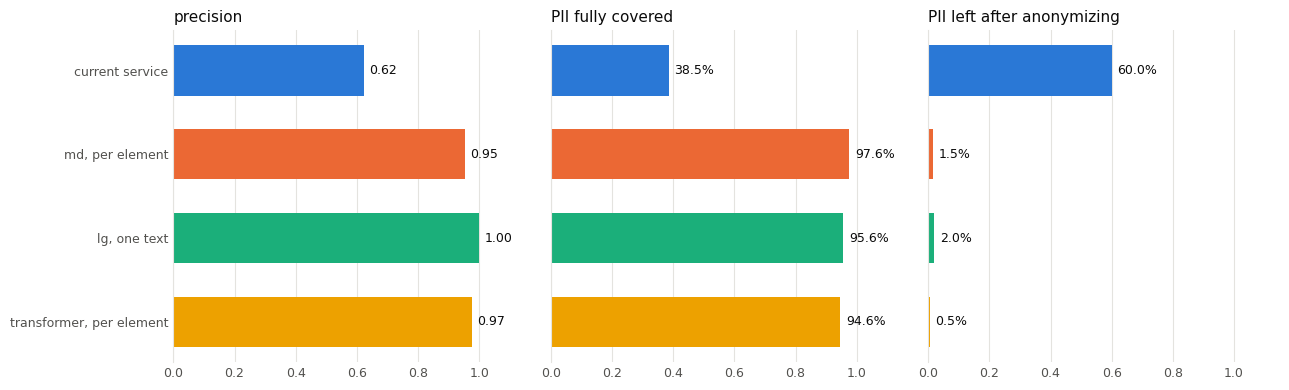

In [3]:
# The current service and the three configurations recommended in notebook 03 (all steps on),
# palette slots 1-4; the values are also in the table above.
shown = {
    "current service": baseline.iloc[0],
    "md, per element": steps.loc[LAST],
    "lg, one text": result(models, ner_model="lg", input_format="one text"),
    "transformer, per element": result(models, ner_model="transformer", input_format="per element"),
}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
panels = ["precision", "recall_full", "residual_pii"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric in zip(axes, panels):
    values = [float(row[metric]) for row in shown.values()]
    bars = ax.barh(range(len(shown)), values, color=COLORS, height=0.6)
    ax.bar_label(bars, labels=[f"{v:.1%}" if metric != "precision" else f"{v:.2f}" for v in values],
                 padding=4, fontsize=9, color=INK)
    ax.set_yticks(range(len(shown)), list(shown) if ax is axes[0] else [""] * len(shown))
    ax.invert_yaxis()
    ax.set_xlim(0, 1.15)
    ax.set_title(METRICS[metric], loc="left", fontsize=11, color=INK)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)
fig.tight_layout()
plt.show()

## Step by step (per element, notebook 01)

In [4]:
steps[["precision", "recall_full", "residual_pii", "false_positives"]].rename(columns=METRICS).round(3)

,precision,PII fully covered,PII left after anonymizing,false positives
approach,,,,
0 baseline,0.622,0.385,0.600,62.0
1 entity filter,0.623,0.346,0.644,49.0
2 thresholds,0.655,0.405,0.585,49.0
3 allow-list,0.727,0.405,0.585,35.0
4 RRN checksum,0.727,0.410,0.585,35.0
5 acronym gate,0.727,0.410,0.585,35.0
6 dedup,0.727,0.410,0.585,35.0
7 documentation + annotations,0.801,0.727,0.254,45.0
8 Belgian recognizers,0.837,0.941,0.029,40.0


## Main conclusions

**What to detect (notebook 01)**
- The biggest gains come from scanning `<documentation>` and text annotations (the service only reads `name`
  attributes) and from Belgian recognizers (phone, rijksregisternummer with spaces, KBO, license plate, address, date
  of birth).
- Restricting the entity types and dropping LOCATION remove most false positives; the allow-list and the
  rijksregisternummer checksum remove a few more. Score thresholds do nothing for names and places (spaCy always
  scores 0.85), and the acronym gate had no measurable effect on this corpus.
- Extending names over surname particles ("Yusuf El Amrani") and masking the parts of approved names reduce what is
  left after anonymizing to 1.5%.
- Side finding: when two entity types tie on the same span and score, the service picks one at random per run.

**How to feed the text (notebook 02)**
- Per element finds the most PII. One text per diagram is 3–4× cheaper (one analyzer call per diagram) and gives a
  cleaner review list, but loses a few names in short labels, which spaCy then labels ORG or WORK_OF_ART.
- The element type prefix helps a little; the order of the lines does not matter; framing as a story makes it
  slightly worse with spaCy, whose NER only looks a few words around each token.

**Which model (notebook 03)**
- spaCy **lg** (same architecture, larger vectors) mainly removes false positives: 2 instead of 10 per element, none
  in one text, at the same speed. It also labels short names as PERSON, which makes the story work.
- A Dutch **transformer** (BERTje) leaves the least PII behind: 0.5% per element, against 1.5% for md. It is about
  10× slower on CPU (≈1 s per diagram), needs the right configuration (aggregation `"first"`), and gets worse in one
  text, where lane names and titles become persons.
- Thresholds do not matter for any model: the transformer's scores are nearly all above 0.95.
- The choice depends on the priority: transformer per element for the least leakage; lg one text for the cleanest
  and cheapest review list; md per element as the middle ground.

**What is still open**
1. Test on real (anonymized) OPH diagrams; the synthetic corpus is optimistic.
2. First names on their own in short labels ("Marleen - Burgerzaken"): a first-name list recognizer, useful for every
   model.
3. One text per diagram without losing short labels: a hybrid with a per-element pass for short labels.
4. Faster transformer detection (GPU, a smaller distilled model, or the transformer only for short labels), or an
   LLM endpoint that reads the whole story of a diagram.